In [1]:
#overstability.ipynb
#by Joe Hahn and Claude Code, joe.hahn@jmh-datasciences.com, 27 November 2026.
#the viscous overstability of axisymmetric epicyclic waves in the self-gravitating ring of density_waves.ipynb (without its
#satellite), the paper's Appendix B; each run seeds one wave of lattice wavenumber phi = pi/4, pi/2 or 3pi/4 (inputs.py,
#tools/patches.py seed_mode) and shows that
#test 14: the wave grows or decays at the rate gamma of Eqn. (B5) (notes/equations.md O7, on the lattice: K = sin^2 phi/Delta^2,
#         x = X(phi)/kappa^2), for shear viscosity alone (with and without ring gravity), bulk viscosity alone,
#         nu_b = nu_s and nu_b = 2 nu_s
#test 15: self-gravity is destabilizing: with nu_b = nu_s and 1600 streamlines, the wave with x below Eqn. (B5)'s onset
#         decays and the two above it grow
#how each quantity is computed, straight from the simulation's output (load3d: every particle's r, v_r):
#  z_j    streamline j's complex amplitude xi_j - i v_r,j/omega, xi_j and v_r,j its particles' mean r and v_r less those of
#         the unseeded control run with the same viscosity, omega = kappa (1 - x)^(1/2) the wave's frequency
#  A(t)   the median |z_j| over the ring's middle 60% (WINDOW), in units of the seeded xi_0
#  gamma  the slope of a straight line fitted to ln A(t)
#  phi(t) the slope of a straight line fitted to the phase of z_j against j; it rises as the wave winds up, so Eqn. (B5)
#         is averaged over the run at phi(t)

In [2]:
#paths and imports
import sys
sys.path.insert(0, '../../source')
sys.path.insert(0, '../../fast')
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt

from overstability_analysis import (load3d, paper_figure, MIXES, PHIS, overstability_run, measured_growth, wave,
    growth_rate, lattice_x, growth_per_K, spacing)

In [3]:
#restore every run: runs[(mix, i)] = (seeded run, the mix's unseeded control)
runs = {(mix, i): (overstability_run('.', mix, i), overstability_run('.', mix, 0)) for mix in MIXES for i in PHIS}
p, o = runs[('S', 2)][0]
print('r.shape = ', o['r'].shape)
for k in ('number_of_streamlines', 'particles_per_streamline', 'radial_width', 'total_ring_mass', 'dt', 'J2', 'Rp',
          'seed_amplitude'):
    print(k, '=', p[k])
for mix, (nu_s, nu_b, gravity, n, steps) in MIXES.items():
    print(mix, ': nu_s, nu_b = ', nu_s, nu_b, '  ring gravity = ', gravity, '  streamlines = ', n)

r.shape =  (50, 800, 32)
number_of_streamlines = 800
particles_per_streamline = 32
radial_width = 0.02
total_ring_mass = 3e-08
dt = 0.5
J2 = 0.01
Rp = 0.5
seed_amplitude = 0.0003
S : nu_s, nu_b =  1e-11 -1.0   ring gravity =  True   streamlines =  800
S0 : nu_s, nu_b =  1e-11 -1.0   ring gravity =  False   streamlines =  800
C : nu_s, nu_b =  0.0 1e-11   ring gravity =  True   streamlines =  800
A : nu_s, nu_b =  1e-11 1e-11   ring gravity =  True   streamlines =  800
D : nu_s, nu_b =  1e-11 2e-11   ring gravity =  True   streamlines =  800
AH : nu_s, nu_b =  2.5e-12 2.5e-12   ring gravity =  True   streamlines =  1600


S   phi/pi = 0.254  x = 0.0427  gamma/K nu: measured +0.3919  Eqn. (B5) +0.3934  ratio 0.9963  ln A residual 0.0041  crossed: None
S   phi/pi = 0.504  x = 0.0726  gamma/K nu: measured +0.4245  Eqn. (B5) +0.4276  ratio 0.9928  ln A residual 0.0017  crossed: None
S   phi/pi = 0.754  x = 0.0905  gamma/K nu: measured +0.4461  Eqn. (B5) +0.4491  ratio 0.9933  ln A residual 0.0042  crossed: None
S0  phi/pi = 0.254  x = 0.0000  gamma/K nu: measured +0.3477  Eqn. (B5) +0.3481  ratio 0.9989  ln A residual 0.0033  crossed: None
S0  phi/pi = 0.504  x = 0.0000  gamma/K nu: measured +0.3471  Eqn. (B5) +0.3481  ratio 0.9972  ln A residual 0.0005  crossed: None
S0  phi/pi = 0.754  x = 0.0000  gamma/K nu: measured +0.3477  Eqn. (B5) +0.3481  ratio 0.9990  ln A residual 0.0026  crossed: None
C   phi/pi = 0.254  x = 0.0427  gamma/K nu: measured -0.5010  Eqn. (B5) -0.5000  ratio 1.0019  ln A residual 0.0044  crossed: None
C   phi/pi = 0.504  x = 0.0726  gamma/K nu: measured -0.5021  Eqn. (B5) -0.5000  ra

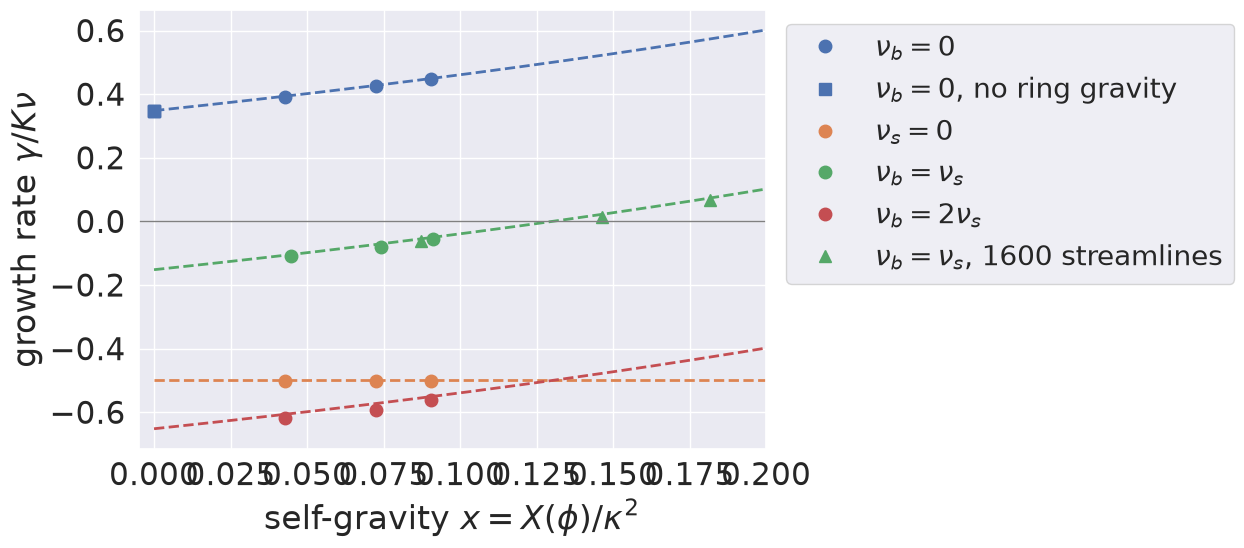

In [4]:
#test 14: each run's measured growth rate versus Eqn. (B5) (the paper's figure, drawn by its own script,
#paper/figures/overstability.py); gamma in units of K nu, nu = nu_s or, with bulk viscosity alone, nu_b
f = paper_figure('overstability').figure(runs)
for (mix, i), ((p, o), (p0, o0)) in runs.items():
    m = measured_growth(p, o, o0)
    nu = max(p['shear_viscosity'], p['bulk_viscosity'])
    print('%-3s phi/pi = %.3f  x = %.4f  gamma/K nu: measured %+.4f  Eqn. (B5) %+.4f  ratio %.4f  ln A residual %.4f  crossed: %s'
        % (mix, m['phi']/np.pi, m['x'], m['gamma']/(m['K']*nu), m['theory']/(m['K']*nu), m['gamma']/m['theory'],
           m['residual'], m['crossed']))

Eqn. (B5) onset for nu_b = nu_s: x_c =  0.1302
phi/pi = 0.259  x = 0.0871  (x - x_c = -0.0431)  amplitude grew by 0.208  gamma measured -5.138e-04  Eqn. (B5) -4.658e-04
phi/pi = 0.510  x = 0.1465  (x - x_c = +0.0163)  amplitude grew by 1.812  gamma measured +1.947e-04  Eqn. (B5) +3.547e-04
phi/pi = 0.760  x = 0.1817  (x - x_c = +0.0515)  amplitude grew by 4.508  gamma measured +4.928e-04  Eqn. (B5) +5.513e-04


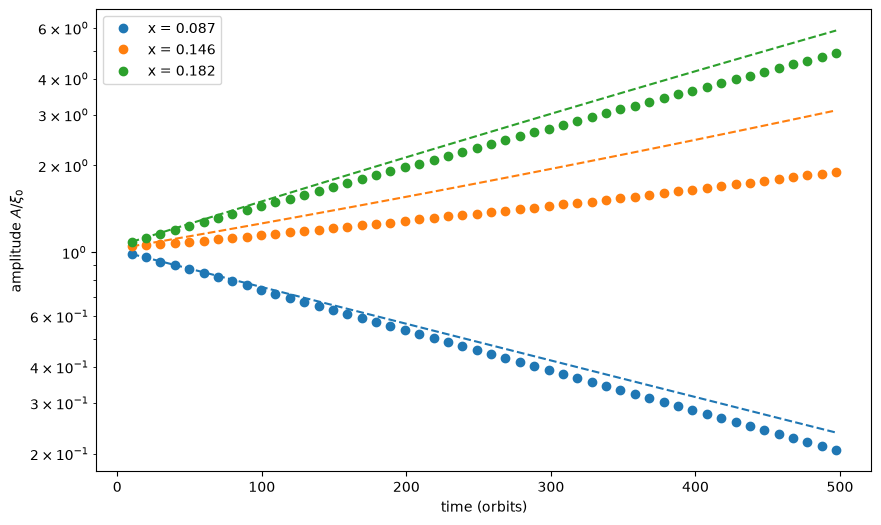

In [5]:
#test 15: the nu_b = nu_s waves at 1600 streamlines: amplitude A(t) (dots) against exp(int gamma dt) with gamma of
#Eqn. (B5) at the wave's wavenumber phi(t) (dashed); the onset, where Eqn. (B5) vanishes, is at x_c
pH = runs[('AH', 1)][0][0]
xs = np.linspace(0.0, 0.3, 30001)
x_c = xs[np.argmin(np.abs(growth_per_K(pH, xs)))]
print('Eqn. (B5) onset for nu_b = nu_s: x_c = ', np.round(x_c, 4))
f, ax = plt.subplots(figsize=(10, 6))
for i in PHIS:
    (p, o), (p0, o0) = runs[('AH', i)]
    t, A, phi = wave(p, o, o0)
    theory = np.array([growth_rate(p, q) for q in phi])
    integral = np.concatenate(([0.0], np.cumsum(0.5*(theory[1:] + theory[:-1])*np.diff(t))))
    line = ax.plot(t/(2*np.pi), A, marker='o', linestyle='none', label='x = %.3f' % lattice_x(p, phi.mean()))
    ax.plot(t/(2*np.pi), A[0]*np.exp(integral), linestyle='dashed', color=line[0].get_color())
    m = measured_growth(p, o, o0)
    print('phi/pi = %.3f  x = %.4f  (x - x_c = %+.4f)  amplitude grew by %.3f  gamma measured %+.3e  Eqn. (B5) %+.3e'
        % (m['phi']/np.pi, m['x'], m['x'] - x_c, m['growth'], m['gamma'], m['theory']))
ax.set_yscale('log')
ax.set_xlabel('time (orbits)')
ax.set_ylabel(r'amplitude $A/\xi_0$')
ax.legend()
plt.show()